Basic imports

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from dataloader import load_transformed_video
#from common.transformations.camera import r
from utils import Calibration, draw_path, FULL_FRAME_SIZE, extract_preds, transform_img, transform_frames, medmodel_intrinsics
from matplotlib.patches import Patch
from model import load_inference_model

#### Basics params

In [2]:
# model inputs constants
MODEL_FREQ = 20
FEATURE_LEN = 512
HISTORY_BUFFER_LEN = 99
DESIRE_LEN = 8
TRAFFIC_CONVENTION_LEN = 2
NAV_FEATURE_LEN = 256
NAV_INSTRUCTION_LEN = 150
LAT_PLANNER_STATE_LEN = 4
LATERAL_CONTROL_PARAMS_LEN = 2
PREV_DESIRED_CURV_LEN = 1

# model outputs constants
FCW_THRESHOLDS_5MS2 = np.array([.05, .05, .15, .15, .15], dtype=np.float32)
FCW_THRESHOLDS_3MS2 = np.array([.7, .7], dtype=np.float32)
FCW_5MS2_PROBS_WIDTH = 5
FCW_3MS2_PROBS_WIDTH = 2

DISENGAGE_WIDTH = 5
POSE_WIDTH = 6
WIDE_FROM_DEVICE_WIDTH = 3
SIM_POSE_WIDTH = 6
LEAD_WIDTH = 4
LANE_LINES_WIDTH = 2
ROAD_EDGES_WIDTH = 2
PLAN_WIDTH = 15
DESIRE_PRED_WIDTH = 8
LAT_PLANNER_SOLUTION_WIDTH = 4
DESIRED_CURV_WIDTH = 1

NUM_LANE_LINES = 4
NUM_ROAD_EDGES = 2

LEAD_TRAJ_LEN = 6
DESIRE_PRED_LEN = 4

PLAN_MHP_N = 5
LEAD_MHP_N = 2
PLAN_MHP_SELECTION = 1
LEAD_MHP_SELECTION = 3

FCW_THRESHOLD_5MS2_HIGH = 0.15
FCW_THRESHOLD_5MS2_LOW = 0.05
FCW_THRESHOLD_3MS2 = 0.7

CONFIDENCE_BUFFER_LEN = 5
RYG_GREEN = 0.01165
RYG_YELLOW = 0.06157

POLY_PATH_DEGREE = 4

In [3]:
X_IDXs = [
        0.,   0.1875,   0.75,   1.6875,   3.,   4.6875,
        6.75,   9.1875,  12.,  15.1875,  18.75,  22.6875,
        27.,  31.6875,  36.75,  42.1875,  48.,  54.1875,
        60.75,  67.6875,  75.,  82.6875,  90.75,  99.1875,
        108., 117.1875, 126.75, 136.6875, 147., 157.6875,
        168.75, 180.1875, 192.]

Run ONNX model on a segment & visualize predictions on a GIF.

In [4]:
plot_img_width, plot_img_height = 640, 480 # can be reduced for wandb

fill_color_gt = [0,  255, 0]
line_color_gt = [255,255, 0]
fill_color_preds = [0,  0,255]
line_color_preds = [200,0,255]
laneline_colors = [(255, 0, 0), (0, 255, 0), (255, 0, 255), (0, 255, 255)]

def legend_color(color, opacity=0.3):
    return np.append(np.array(color)/255, opacity)

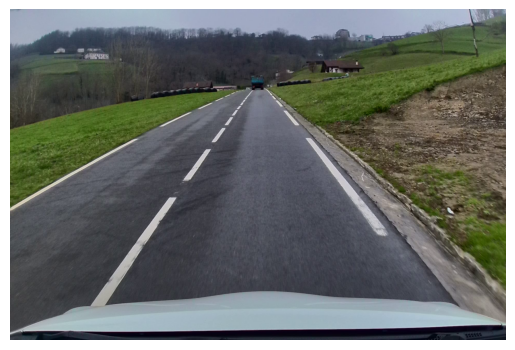

In [3]:
import cv2 
import matplotlib.pyplot as plt

path_to_segment = '../videos/recta-1.avi'
segment_video = cv2.VideoCapture(path_to_segment)

ret, frame = segment_video.read()
rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
plt.imshow(rgb_frame)
plt.axis('off')
plt.show()

In [ ]:
GT: xlims (0.0, 333.1179262491538),  ylims (-0.0638889495916598, 52.201398447671515)
GT Filtred: xlims (0.0, 192.02717778060045),  ylims (-0.0638889495916598, 34.253137688214636)
PRED: xlims (0.014596071094274521, 192.42918395996094),  ylims (0.12123946100473404, 66.2313461303711)  

[[0.]
 [0.]
 [0.]]


### Load transformed and raw RGB video

In [5]:
#path_to_segment = '/home/nikita/data/2021-09-14--09-19-21/25'
#path_to_segment = '/home/VICOMTECH/gortiz/Proyectos/Mendi4U/3_Datasets/videos/vlc-record.hevc'
#path_to_segment = '/home/VICOMTECH/gortiz/Proyectos/Mendi4U/3_Datasets/videos/video.hevc'
path_to_segment = '../videos/video_gps.avi'
OLD_MODEL = '../common/models/supercombo_viejo.onnx'
ORIGINAL_MODEL = '../common/models/supercombo.onnx'

os.makedirs('outs', exist_ok=True)

seq_len = 250

input_frames, rgb_frames, yuv_frames, seq_len = load_transformed_video(path_to_segment, seq_len=seq_len)

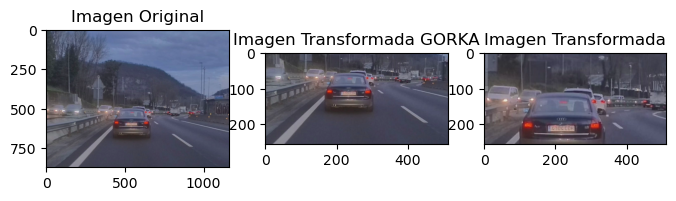

In [6]:
import cv2
import numpy as np
from scipy.spatial.transform import Rotation as R
#from config import FULL_FRAME_SIZE
from utils import transform_img_gorka, transform_img


base_img = yuv_frames[10]

# [Forward, Right, Down]
#0.09682, 1.7769,-1.33505
#rvec = np.deg2rad(np.array([1.25485843, -1.27927087, 1.17724224]))
rvec = np.deg2rad(np.array([2.25485843, 0.0, 0.0]))
tvec = np.array([0.0, 0.0, 0.0])
#tvec = np.array([0.0,0.0,2.33505])



# Aplicar la transformación
transformed_img_gorka = transform_img_gorka(
    base_img,
    #augment_eulers=rvec,    
    #augment_trans=tvec,
    #from_intr=eon_intrinsics,
    #to_intr=medmodel_intrinsics, 
    top_hacks=False,
    yuv=True,
    output_size=(512, 256)
)

# Aplicar la transformación
transformed_img = transform_img(
    base_img,
    #augment_eulers=rvec,    
    #augment_trans=tvec,
    #from_intr=eon_intrinsics,
    #to_intr=medmodel_intrinsics, 
    top_hacks=False,
    yuv=True,
    output_size=(512, 256)
)

# Mostrar las imágenes antes y después de la transformación
plt.figure(figsize=(8, 5))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(base_img, cv2.COLOR_YUV2RGB_I420))
plt.title("Imagen Original")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(transformed_img_gorka, cv2.COLOR_YUV2RGB_I420))
plt.title("Imagen Transformada GORKA")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(transformed_img, cv2.COLOR_YUV2RGB_I420))
plt.title("Imagen Transformada")

plt.show()

(874, 1160, 3)


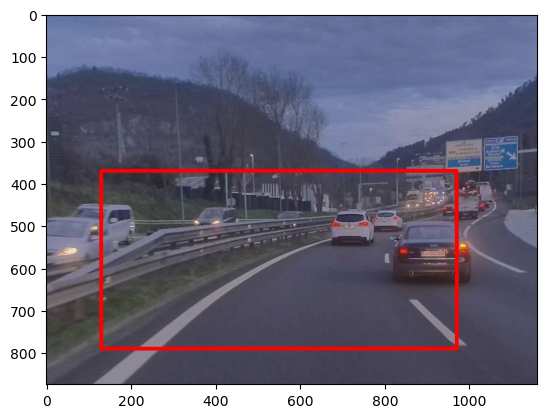

In [35]:
t_idx = 100
base_img = cv2.cvtColor(yuv_frames[t_idx], cv2.COLOR_YUV2RGB_I420)
print(base_img.shape)
start_point = np.array([130, 370]) 
size = np.array([840, 420])
end_point = start_point + size
image_crop = base_img[start_point[1]:end_point[1], start_point[0]:end_point[0]]
image_resize_crop = cv2.resize(image_crop, (512, 256))
plt.imshow(cv2.rectangle(base_img, start_point, end_point, (255, 0, 0), thickness=8))
plt.show()


In [36]:
from common.transformations.camera import normalize
import common.transformations.orientation as orient

def get_M(size, cy, augment_eulers, augment_trans, to_intr, from_intr, h=1.22):
    quadrangle = np.array([[0, cy + 20], 
                        [size[1]-1, cy + 20],
                        [0, size[0]-1],
                        [size[1]-1, size[0]-1]], dtype=np.float32)
    quadrangle_norm = np.hstack((normalize(quadrangle, intrinsics=from_intr), np.ones((4, 1))))
    quadrangle_world = np.column_stack((h*quadrangle_norm[:, 0]/quadrangle_norm[:, 1],
                                        h*np.ones(4),
                                        h/quadrangle_norm[:, 1]))
    rot = orient.rot_from_euler(augment_eulers)
    to_extrinsics = np.hstack((rot.T, -augment_trans[:, None]))
    to_KE = to_intr.dot(to_extrinsics)
    warped_quadrangle_full = np.einsum('jk,ik->ij', to_KE, np.hstack((quadrangle_world, np.ones((4, 1)))))        
    warped_quadrangle = np.column_stack((warped_quadrangle_full[:, 0]/warped_quadrangle_full[:, 2],
                                        warped_quadrangle_full[:, 1]/warped_quadrangle_full[:, 2])).astype(np.float32)        
    M = cv2.getPerspectiveTransform(quadrangle, warped_quadrangle.astype(np.float32))
    return M

(324, 389)
(835, 389)
(835, 644)
(324, 644)


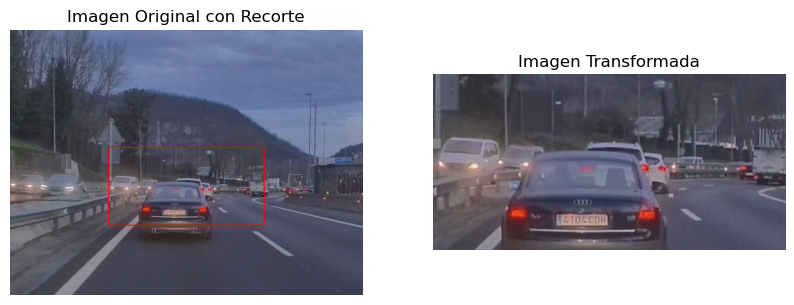

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar imagen original en YUV y convertir a RGB
original_rgb = cv2.cvtColor(base_img, cv2.COLOR_YUV2RGB_I420)

augment_eulers = np.array([0.0, 0.0, 0.0])
augment_trans = np.array([0.0, 0.0, 0.0])

FULL_FRAME_SIZE = (1160, 874)
W, H = FULL_FRAME_SIZE[0], FULL_FRAME_SIZE[1]
#eon_intrinsics = np.array([
#    [ 1.84458100e+03, 0., 7.27282344e+02],
#    [ 0., 1.84256784e+03, 7.13818149e+02],
#    [ 0., 0., 1. ]])
#eon_focal_length = FOCAL = (eon_intrinsics[0,0] + eon_intrinsics[1,1])/2
eon_focal_length = FOCAL = 910
eon_intrinsics = np.array([
  [FOCAL,   0.,   W/2.],
  [  0.,  FOCAL,  H/2.],
  [  0.,    0.,     1.]])

# MED model
MEDMODEL_INPUT_SIZE = (512, 256)
MEDMODEL_YUV_SIZE = (MEDMODEL_INPUT_SIZE[0], MEDMODEL_INPUT_SIZE[1] * 3 // 2)
MEDMODEL_CY = 47.6
#MEDMODEL_CY = MEDMODEL_INPUT_SIZE[1]/2

medmodel_zoom = 1.
medmodel_intrinsics = np.array(
  [[ eon_focal_length / medmodel_zoom,    0. ,  0.5 * MEDMODEL_INPUT_SIZE[0]],
   [   0. ,  eon_focal_length / medmodel_zoom,  MEDMODEL_CY],
   [   0. ,                            0. ,   1.]])

from_intr = eon_intrinsics
to_intr = medmodel_intrinsics
size = original_rgb.shape[:2]
cy = from_intr[1, 2]
h = 10


M = get_M(size, cy, augment_eulers, augment_trans, to_intr, from_intr, h)

# Definir el tamaño de la imagen transformada
output_size = (512, 256)

# Definir los cuatro puntos de la imagen de salida
dst_pts = np.array([[0, 0], [output_size[0]-1, 0], 
                    [0, output_size[1]-1], [output_size[0]-1, output_size[1]-1]], dtype=np.float32)

# Obtener los puntos correspondientes en la imagen original invirtiendo la transformación
M_inv = np.linalg.inv(M)
src_pts = cv2.perspectiveTransform(dst_pts.reshape(-1, 1, 2), M_inv).reshape(-1, 2)

src_pts = np.array([src_pts[0], src_pts[1], src_pts[3], src_pts[2]])
# Dibujar el cuadrilátero en la imagen original
original_with_bbox = original_rgb.copy()
for i in range(4):
    pt1 = tuple(map(int, src_pts[i]))
    pt2 = tuple(map(int, src_pts[(i+1) % 4]))  # Conectar con el siguiente punto
    print(pt1)
    cv2.line(original_with_bbox, pt1, pt2, (255, 0, 0), 2)  # Línea azul

# Aplicar la transformación y mostrar ambas imágenes
augmented_rgb = cv2.warpPerspective(original_rgb, M, output_size, borderMode=cv2.BORDER_REPLICATE)

# Mostrar las imágenes con matplotlib
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Imagen Original con Recorte")
plt.imshow(original_with_bbox)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Imagen Transformada")
plt.imshow(augmented_rgb)
plt.axis("off")

plt.show()


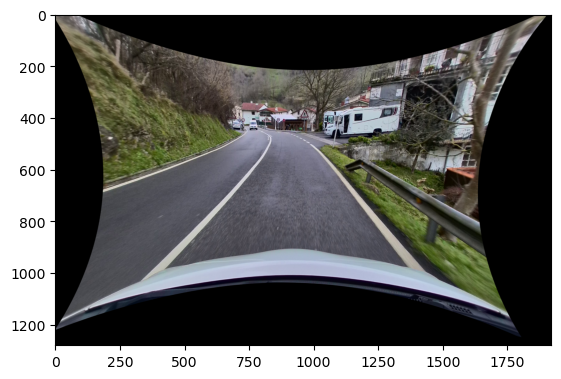

In [31]:
import cv2
import numpy as np

# Matriz intrínseca de la cámara
camera_matrix = np.array([[1.79905770e+03, 0.00000000e+00, 9.76952521e+02],
                          [0.00000000e+00, 1.80329984e+03, 6.92947142e+02],
                          [0.00000000e+00, 0.00000000e+00, 1.00000000e+00]])

# Coeficientes de distorsión
dist_coeffs = np.array([-0.46803735, 0.27962654, -0.00422529, -0.00396602, -0.13697077])

# Vector de rotación (sin traslación)
rvec = -np.deg2rad(np.array([[1.25485843], [-1.27927087], [1.17724224]]))

# Cargar la imagen
image = frame2

# Paso 1: Corregir la distorsión
h, w = image.shape[:2]
new_camera_matrix, roi = cv2.getOptimalNewCameraMatrix(camera_matrix, dist_coeffs, (w, h), 1, (w, h))
undistorted_image = cv2.undistort(image, camera_matrix, dist_coeffs, None, new_camera_matrix)

# Paso 2: Obtener la matriz de rotación
R, _ = cv2.Rodrigues(rvec)  # Convertir el vector de rotación en matriz
R_inv = np.linalg.inv(R)    # Invertir la rotación para corregir la imagen

# Paso 3: Crear la nueva transformación sin traslación
map1, map2 = cv2.initUndistortRectifyMap(camera_matrix, dist_coeffs, R_inv, new_camera_matrix, (w, h), cv2.CV_16SC2)
#corrected_image = cv2.remap(undistorted_image, map1, map2, cv2.INTER_LINEAR)
corrected_image = cv2.remap(undistorted_image, map1, map2, cv2.INTER_CUBIC)

# Mostrar y guardar el resultado
plt.imshow(cv2.cvtColor(corrected_image, cv2.COLOR_BGR2RGB))
plt.show()


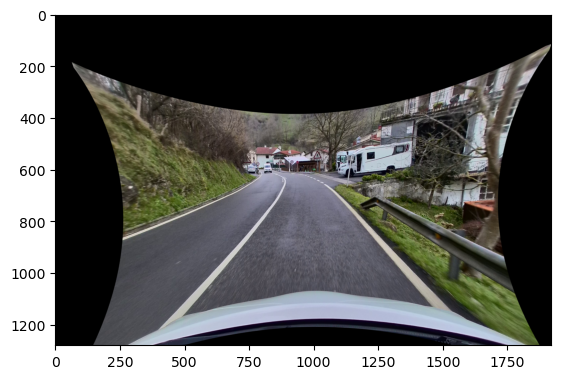

In [48]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def correct_image_perspective(image, camera_matrix, dist_coeffs, rvec):
    """
    Corrige la perspectiva de una imagen eliminando la distorsión y aplicando una transformación de rotación.

    Parámetros:
    image (numpy.ndarray): Imagen de entrada en formato BGR.
    camera_matrix (numpy.ndarray): Matriz intrínseca de la cámara.
    dist_coeffs (numpy.ndarray): Coeficientes de distorsión de la cámara.
    rvec (numpy.ndarray): Vector de rotación en radianes.

    Retorna:
    numpy.ndarray: Imagen corregida en perspectiva.
    """
    # Obtener dimensiones de la imagen
    h, w = image.shape[:2]
    
    # Calcular la nueva matriz de cámara óptima
    new_camera_matrix, roi = cv2.getOptimalNewCameraMatrix(camera_matrix, dist_coeffs, (w, h), 1, (w, h))
    
    # Corregir la distorsión de la imagen
    undistorted_image = cv2.undistort(image, camera_matrix, dist_coeffs, None, new_camera_matrix)
    
    # Convertir el vector de rotación en matriz de rotación
    R, _ = cv2.Rodrigues(rvec)
    R_inv = np.linalg.inv(R)  # Invertir la rotación para corregir la imagen
    
    # Crear la nueva transformación sin traslación
    map1, map2 = cv2.initUndistortRectifyMap(camera_matrix, dist_coeffs, R_inv, new_camera_matrix, (w, h), cv2.CV_16SC2)
    corrected_image = cv2.remap(undistorted_image, map1, map2, cv2.INTER_CUBIC)
    
    return corrected_image

# Datos de la cámara
camera_matrix = np.array([[1.79905770e+03, 0.00000000e+00, 9.76952521e+02],
                          [0.00000000e+00, 1.80329984e+03, 6.92947142e+02],
                          [0.00000000e+00, 0.00000000e+00, 1.00000000e+00]])

dist_coeffs = np.array([-0.46803735, 0.27962654, -0.00422529, -0.00396602, -0.13697077])

# Vector de rotación en radianes
#rvec = np.deg2rad(np.array([[1.25485843], [-1.27927087], [1.17724224]]))
rvec = np.deg2rad(np.array([[5.25485843], [-1.27927087], [1.17724224]]))

# Cargar la imagen (debe estar previamente definida como frame2)
corrected_image = correct_image_perspective(frame2, camera_matrix, dist_coeffs, rvec)

# Mostrar el resultado
plt.imshow(cv2.cvtColor(corrected_image, cv2.COLOR_BGR2RGB))
plt.show()

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

segment_video = cv2.VideoCapture("../videos/camino-ciudad-1.avi")
ret, frame2 = segment_video.read()

segment_video = cv2.VideoCapture("../videos/video.hevc")
ret, frame3 = segment_video.read()


# Cargar imagen original en YUV y convertir a RGB
original_rgb = cv2.resize(cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB), (1164, 874))
corrected_rgb = cv2.resize(cv2.cvtColor(corrected_image, cv2.COLOR_BGR2RGB), (1164, 874))
sample_rgb = cv2.resize(cv2.cvtColor(frame3, cv2.COLOR_BGR2RGB), (1164, 874))

# Matriz de transformación (perspectiva)
M = np.array([[1.00000000e+00,  0.00000000e+00, -3.26000000e+02],
              [7.94243757e-18,  1.00000002e+00, -3.89400010e+02],
              [1.17491685e-19, -0.00000000e+00,  1.00000000e+00]])

# Definir el tamaño de la imagen transformada
output_size = (512, 256)

# Definir los cuatro puntos de la imagen de salida
dst_pts = np.array([[0, 0], [output_size[0]-1, 0], 
                    [0, output_size[1]-1], [output_size[0]-1, output_size[1]-1]], dtype=np.float32)

# Obtener los puntos correspondientes en la imagen original invirtiendo la transformación
M_inv = np.linalg.inv(M)
src_pts = cv2.perspectiveTransform(dst_pts.reshape(-1, 1, 2), M_inv).reshape(-1, 2)

src_pts = np.array([src_pts[0], src_pts[1], src_pts[3], src_pts[2]])
# Dibujar el cuadrilátero en la imagen original
original_with_bbox = original_rgb.copy()
for i in range(4):
    pt1 = tuple(map(int, src_pts[i]))
    pt2 = tuple(map(int, src_pts[(i+1) % 4]))  # Conectar con el siguiente punto
    cv2.line(original_with_bbox, pt1, pt2, (255, 0, 0), 2)  # Línea azul

# Aplicar la transformación y mostrar ambas imágenes
orignial_augmented_rgb = cv2.warpPerspective(original_rgb, M, output_size, borderMode=cv2.BORDER_REPLICATE)

corrected_with_bbox = corrected_rgb.copy()
for i in range(4):
    pt1 = tuple(map(int, src_pts[i]))
    pt2 = tuple(map(int, src_pts[(i+1) % 4]))  # Conectar con el siguiente punto
    cv2.line(corrected_with_bbox, pt1, pt2, (255, 0, 0), 2)  # Línea azul

# Aplicar la transformación y mostrar ambas imágenes
corrected_augmented_rgb = cv2.warpPerspective(corrected_rgb, M, output_size, borderMode=cv2.BORDER_REPLICATE)

sample_with_bbox = sample_rgb.copy()
for i in range(4):
    pt1 = tuple(map(int, src_pts[i]))
    pt2 = tuple(map(int, src_pts[(i+1) % 4]))  # Conectar con el siguiente punto
    cv2.line(sample_with_bbox, pt1, pt2, (255, 0, 0), 2)  # Línea azul

# Aplicar la transformación y mostrar ambas imágenes
sample_augmented_rgb = cv2.warpPerspective(sample_rgb, M, output_size, borderMode=cv2.BORDER_REPLICATE)


# Mostrar las imágenes con matplotlibç
fig, axis = plt.subplots(3, 2, figsize=(10, 10))
axes = axis.ravel()

axes[0].set_title("Ejemplo con Recorte")
axes[0].imshow(sample_with_bbox)
axes[0].axis("off")

axes[1].set_title("Imagen Ejemplo Recortada")
axes[1].imshow(sample_augmented_rgb)
axes[1].axis("off")

axes[2].set_title("Imagen Original con Recorte")
axes[2].imshow(original_with_bbox)
axes[2].axis("off")

axes[3].set_title("Imagen Original Recortada")
axes[3].imshow(orignial_augmented_rgb)
axes[3].axis("off")

axes[4].set_title("Imagen Corregida con Recorte")
axes[4].imshow(corrected_with_bbox)
axes[4].axis("off")

axes[5].set_title("Imagen Corregida Recortada")
axes[5].imshow(corrected_augmented_rgb)
axes[5].axis("off")


plt.tight_layout()
plt.show()

NameError: name 'corrected_image' is not defined

## Modelo antiguo

### Load model

In [ ]:
model, run_model = load_inference_model(OLD_MODEL)

### Run model

In [ ]:
lanelines_preds = []
road_edges_preds = []
path_preds = []

recurrent_state = np.zeros((1, 512), dtype=np.float32)

for t_idx in range(seq_len):
    inputs = {
        'input_imgs': input_frames[t_idx:t_idx+1].numpy().astype(np.float32),
        #'input_imgs': input_frames[t_idx].numpy().astype(np.float32),
        'desire': np.zeros((1, 8), dtype=np.float32),
        'traffic_convention': np.array([0, 1], dtype=np.float32).reshape(1, 2),
        'initial_state': recurrent_state,
    }

    outs, recurrent_state = run_model(inputs)
    
    lanelines, road_edges, best_path = extract_preds(outs)[0]

    lanelines_preds.append(lanelines)
    road_edges_preds.append(road_edges)
    path_preds.append(best_path)

### Create gif

In [ ]:
from matplotlib.animation import FuncAnimation, FFMpegWriter

camara_height = 1.1
car_width = 0.2
plot_width = 12
plot_height = plot_width * (FULL_FRAME_SIZE[1] / FULL_FRAME_SIZE[0])
fig, ax = plt.subplots(1,1, figsize=(plot_width, plot_height))

def animate(t_idx):
    # real calibration values during this ride, divided by 2 to account for not using calibration during inference
    rpy_calib_pred = np.array([0.00018335809, 0.034165092, -0.014245722]) / 2 
    #rpy_calib_pred = np.array([0.00, 0.00, 0.00]) 
    calibration = Calibration(rpy_calib_pred, plot_img_width=plot_img_width, plot_img_height=plot_img_height)

    img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)    

    ax.clear()
    txt = ax.text(plot_img_height-100, plot_img_width-100, f'Frame {t_idx}', fontsize=20)
    plt_img = ax.imshow(img_plot)

    return txt, plt_img

anim = FuncAnimation(fig, animate, interval=1000/20, blit=True, repeat=True, frames=len(path_preds))  
writer = FFMpegWriter(fps=20, bitrate=2000)
anim.save("outs/TLI_OLD_TEST.gif", writer=writer)

## Nuevo Modelo

#### Load model

In [6]:
model_new, run_model_new = load_inference_model(ORIGINAL_MODEL)

#### Run model

In [7]:
v_ego = 10 # km/h, simulación
steer_delay = 0.01 # s

lanelines_preds = []
road_edges_preds = []
path_preds = []

desire_data = np.array([0]).astype('float32')
desire_data.resize((1,8))

traffic_convention_data = np.array([0]).astype('float32')
traffic_convention_data.resize((1,512))

initial_state_data = np.array([0]).astype('float32')
initial_state_data.resize((1,2))

recurrent_state = np.zeros((1, 512), dtype=np.float32)

for t_idx in range(seq_len):

    inputs = {
        'input_imgs': input_frames[t_idx:t_idx+1].numpy().astype(np.float32),
        'desire': desire_data,
        'traffic_convention': np.array([0, 1], dtype=np.float32).reshape(1, 2),
        'initial_state': recurrent_state
        }
    outs, recurrent_state = run_model_new(inputs)
    #print(type(outs), outs.shape)

    lanelines, road_edges, best_path = extract_preds(outs)[0]

    lanelines_preds.append(lanelines)
    road_edges_preds.append(road_edges)
    path_preds.append(best_path)


#### Create GIFF

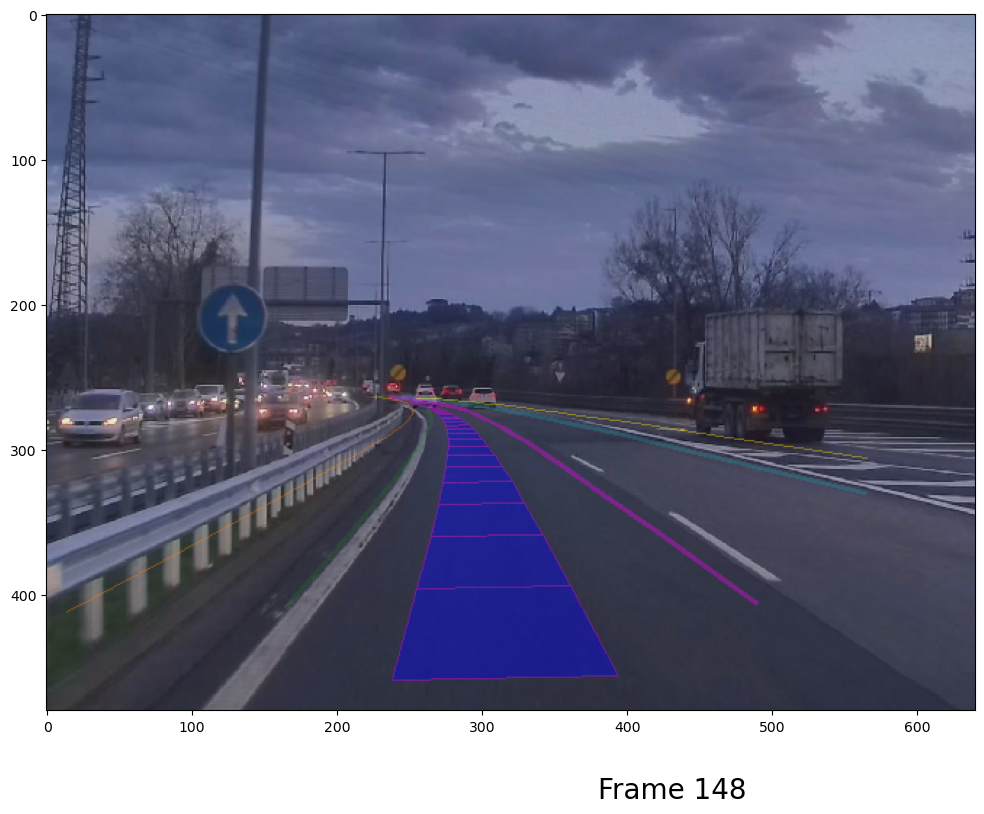

In [8]:
from matplotlib.animation import FuncAnimation, FFMpegWriter

t_idx = 148
camara_height = 1.5
car_width = 0.6
plot_width = 12
plot_height = plot_width * (FULL_FRAME_SIZE[1] / FULL_FRAME_SIZE[0])
fig, ax = plt.subplots(1,1, figsize=(plot_width, plot_height))

rpy_calib_pred = np.array([0.0, -0.05, -0.05])
calibration = Calibration(rpy_calib_pred, plot_img_width=plot_img_width, plot_img_height=plot_img_height)

img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)    

ax.clear()
txt = ax.text(plot_img_height-100, plot_img_width-100, f'Frame {t_idx}', fontsize=20)
plt_img = ax.imshow(img_plot)

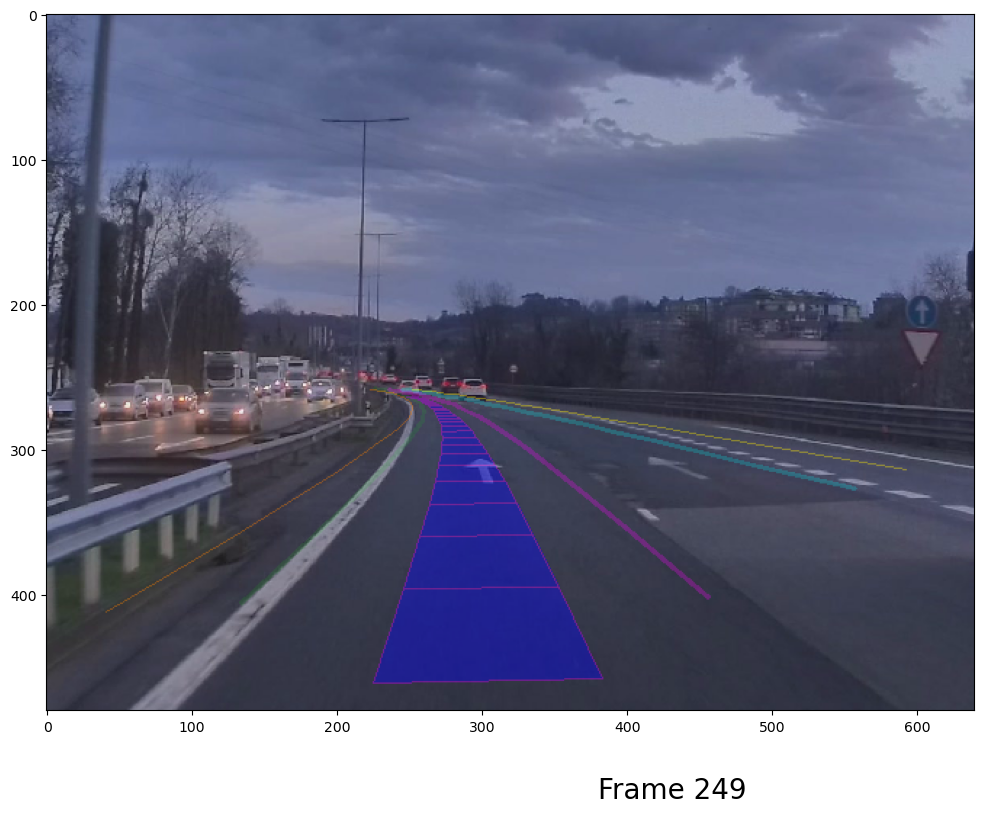

In [9]:
from matplotlib.animation import FuncAnimation, FFMpegWriter

camara_height = 1.5
car_width = 0.6
plot_width = 12
plot_height = plot_width * (FULL_FRAME_SIZE[1] / FULL_FRAME_SIZE[0])
fig, ax = plt.subplots(1,1, figsize=(plot_width, plot_height))

def animate(t_idx):
    rpy_calib_pred = np.array([0.0, -0.05, -0.05])
    calibration = Calibration(rpy_calib_pred, plot_img_width=plot_img_width, plot_img_height=plot_img_height)

    img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)    

    ax.clear()
    txt = ax.text(plot_img_height-100, plot_img_width-100, f'Frame {t_idx}', fontsize=20)
    plt_img = ax.imshow(img_plot)

    return txt, plt_img

anim = FuncAnimation(fig, animate, interval=1000/20, blit=True, repeat=True, frames=len(path_preds))  
writer = FFMpegWriter(fps=20, bitrate=2000)
anim.save("outs/TLI_NEW.gif", writer=writer)

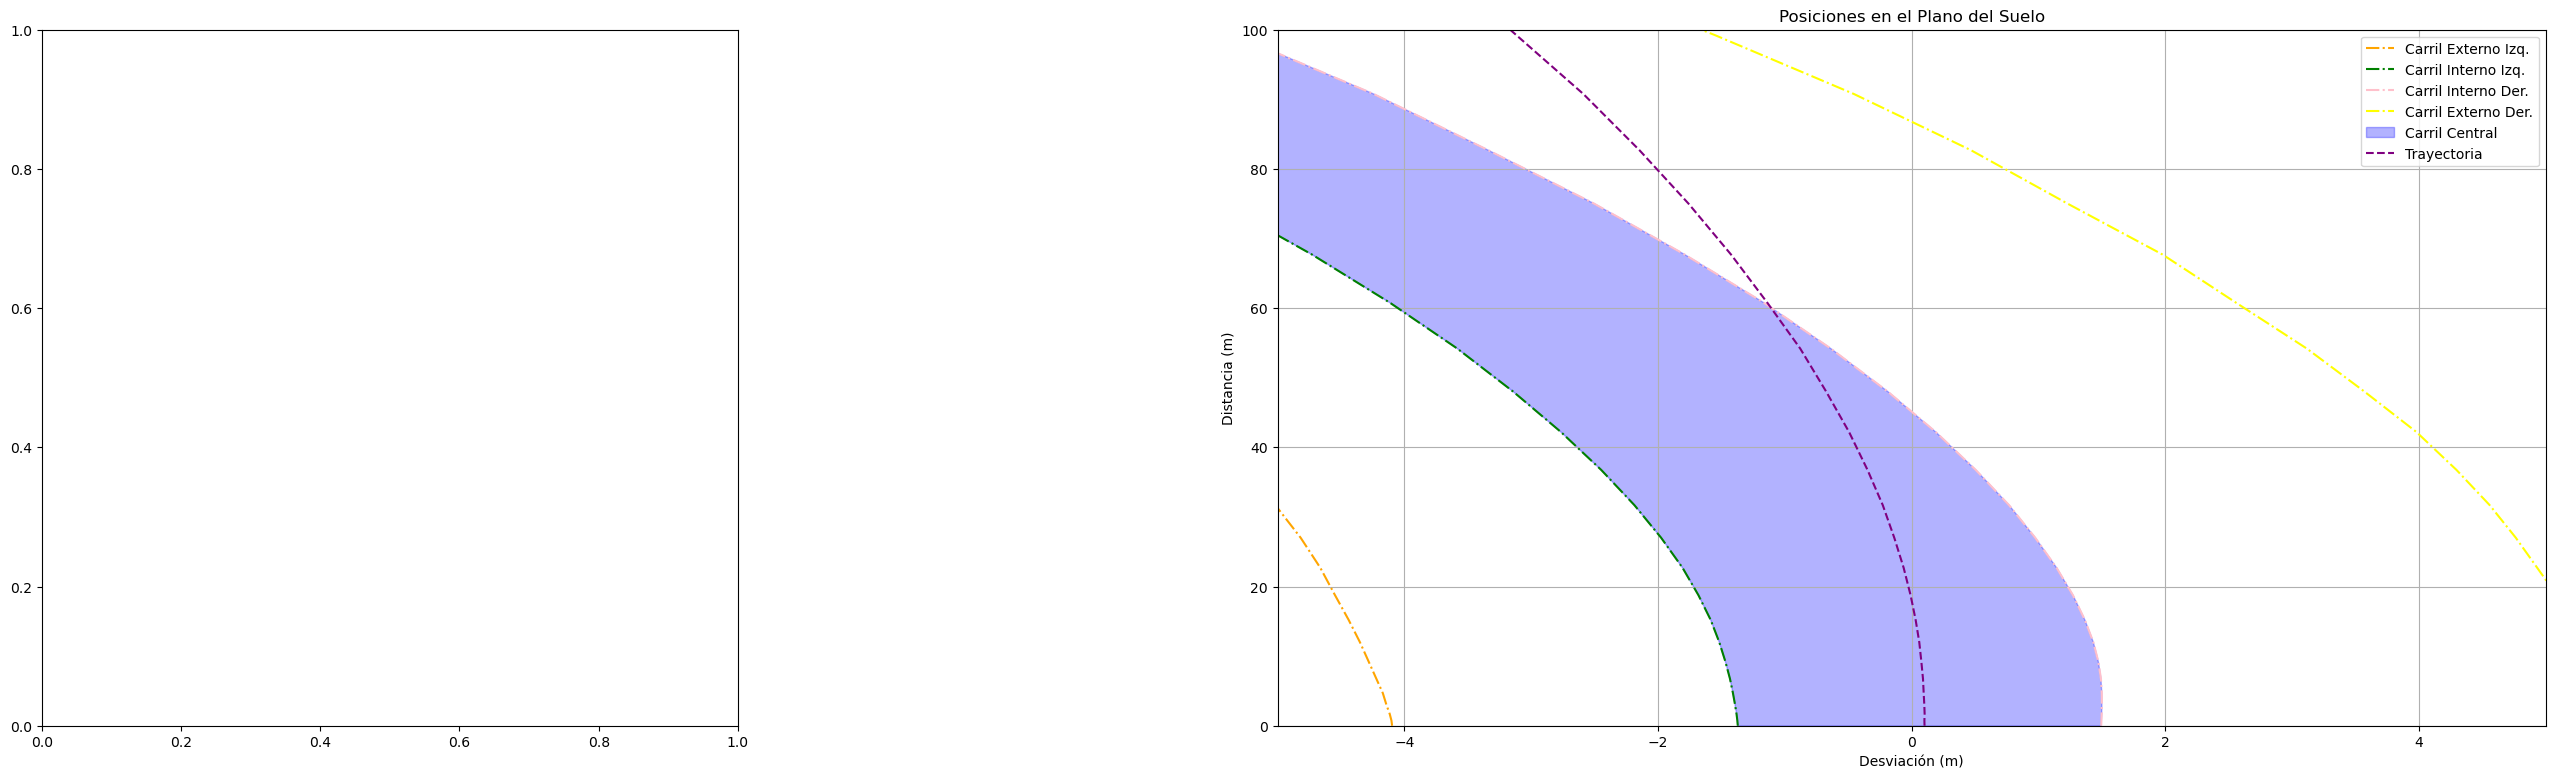

In [10]:
from matplotlib.animation import FuncAnimation, FFMpegWriter
import matplotlib.pyplot as plt

camara_height = 1.1
car_width = 0.2
plot_width = 12
plot_height = plot_width * (FULL_FRAME_SIZE[1] / FULL_FRAME_SIZE[0])

# Crear una figura con 2 columnas
fig, (ax_img, ax_plot) = plt.subplots(1, 2, figsize=(plot_width * 3, plot_height))

def animate(t_idx):
    # Real calibration values during this ride, divided by 2 to account for not using calibration during inference
    rpy_calib_pred = np.array([0.00, 0.00, 0.00]) 
    calibration = Calibration(rpy_calib_pred, plot_img_width=plot_img_width, plot_img_height=plot_img_height)

    # Primera columna: Imagen con carriles y trayectoria proyectada
    img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)    

    ax_img.clear()
    txt = ax_img.text(plot_img_height-100, plot_img_width-100, f'Frame {t_idx}', fontsize=20)
    ax_img.imshow(img_plot)
    
    # Segunda columna imagen tranformada
    ax_plot.clear()
    ax_img.clear()    

    # Tercera columna: Gráfico en el plano del suelo
    ax_plot.clear()
    ax_plot.set_title("Posiciones en el Plano del Suelo")
    ax_plot.set_xlabel("Desviación (m)")
    ax_plot.set_ylabel("Distancia (m)")
    ax_plot.grid(True)
    ax_plot.set_xlim(-5, 5)
    ax_plot.set_ylim(0, 100)

    # Extraer y graficar las posiciones en el plano del suelo
    fixed_distances = np.array(X_IDXs)[:, np.newaxis]

    if lanelines_preds[t_idx] is not None:
        (oll, ill, irl, orl), _ = lanelines_preds[t_idx]
        oll = np.array(oll)
        ill = np.array(ill)
        irl = np.array(irl)
        orl = np.array(orl)

        # Graficar líneas de carril
        ax_plot.plot(oll[:, 0], fixed_distances, label='Carril Externo Izq.', color='orange', linestyle='-.')
        ax_plot.plot(ill[:, 0], fixed_distances, label='Carril Interno Izq.', color='green', linestyle='-.')
        ax_plot.plot(irl[:, 0], fixed_distances, label='Carril Interno Der.', color='pink', linestyle='-.')
        ax_plot.plot(orl[:, 0], fixed_distances, label='Carril Externo Der.', color='yellow', linestyle='-.')

        # Rellenar espacio entre carril interior izquierdo y derecho
        ax_plot.fill_betweenx(
            fixed_distances.flatten(), 
            ill[:, 0], 
            irl[:, 0], 
            color='blue', 
            alpha=0.3,   # Transparencia (0.0 = completamente transparente, 1.0 = opaco)
            label='Carril Central'
        )

    if path_preds[t_idx] is not None:
        path_plan = path_preds[t_idx][0, :, :3]
        ax_plot.plot(path_plan[:, 1], fixed_distances, label='Trayectoria', color='purple', linestyle='--')

    ax_plot.legend()

    return txt,

anim = FuncAnimation(fig, animate, interval=1000/20, blit=True, repeat=True, frames=len(path_preds))  
writer = FFMpegWriter(fps=20, bitrate=2000)
anim.save("outs/TLI_NEW_DOUBLE.gif", writer=writer)

## ESCENARIOS SIGNIFICATIVOS Mendi4U

In [ ]:
ORIGINAL_MODEL = '../common/models/supercombo.onnx'
model, run_model = load_inference_model(ORIGINAL_MODEL)

path_to_segment = '../videos/'
os.makedirs('outs', exist_ok=True)

### Recta 1

<img src = "../images/recta-1.png" width=600 height=400>

In [ ]:

segment_name = 'recta-1'

input_frames, rgb_frames, seq_len = load_transformed_video(path_to_segment + segment_name + '.avi')

In [ ]:
lanelines_preds = []
road_edges_preds = []
path_preds = []

recurrent_state = np.zeros((1, 512), dtype=np.float32)

for t_idx in range(seq_len):
    inputs = {
        'input_imgs': input_frames[t_idx:t_idx+1].numpy().astype(np.float32),
        'desire': np.zeros((1, 8), dtype=np.float32),
        'traffic_convention': np.array([0, 1], dtype=np.float32).reshape(1, 2),
        'initial_state': recurrent_state,
    }

    outs, recurrent_state = run_model(inputs)
    lanelines, road_edges, best_path = extract_preds(outs)[0]

    lanelines_preds.append(lanelines)
    road_edges_preds.append(road_edges)
    path_preds.append(best_path)

In [ ]:
from matplotlib.animation import FuncAnimation, FFMpegWriter
import matplotlib.pyplot as plt

camara_height = 1.1
car_width = 0.2
plot_width = 12
plot_height = plot_width * (FULL_FRAME_SIZE[1] / FULL_FRAME_SIZE[0])

# Crear una figura con 2 columnas
fig, (ax_img, ax_plot) = plt.subplots(1, 2, figsize=(plot_width * 2, plot_height))

def animate(t_idx):
    # Real calibration values during this ride, divided by 2 to account for not using calibration during inference
    rpy_calib_pred = np.array([0.00, 0.00, 0.00]) 
    calibration = Calibration(rpy_calib_pred, plot_img_width=plot_img_width, plot_img_height=plot_img_height)

    # Primera columna: Imagen con carriles y trayectoria proyectada
    img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)    

    ax_img.clear()
    txt = ax_img.text(plot_img_height-100, plot_img_width-100, f'Frame {t_idx}', fontsize=20)
    ax_img.imshow(img_plot)

    # Segunda columna: Gráfico en el plano del suelo
    ax_plot.clear()
    ax_plot.set_title("Posiciones en el Plano del Suelo")
    ax_plot.set_xlabel("Desviación (m)")
    ax_plot.set_ylabel("Distancia (m)")
    ax_plot.grid(True)
    ax_plot.set_xlim(-5, 5)
    ax_plot.set_ylim(0, 100)

    # Extraer y graficar las posiciones en el plano del suelo
    fixed_distances = np.array(X_IDXs)[:, np.newaxis]

    if lanelines_preds[t_idx] is not None:
        (oll, ill, irl, orl), _ = lanelines_preds[t_idx]
        oll = np.array(oll)
        ill = np.array(ill)
        irl = np.array(irl)
        orl = np.array(orl)

        # Graficar líneas de carril
        ax_plot.plot(oll[:, 0], fixed_distances, label='Carril Externo Izq.', color='orange', linestyle='-.')
        ax_plot.plot(ill[:, 0], fixed_distances, label='Carril Interno Izq.', color='green', linestyle='-.')
        ax_plot.plot(irl[:, 0], fixed_distances, label='Carril Interno Der.', color='pink', linestyle='-.')
        ax_plot.plot(orl[:, 0], fixed_distances, label='Carril Externo Der.', color='yellow', linestyle='-.')

        # Rellenar espacio entre carril interior izquierdo y derecho
        ax_plot.fill_betweenx(
            fixed_distances.flatten(), 
            ill[:, 0], 
            irl[:, 0], 
            color='blue', 
            alpha=0.3,   # Transparencia (0.0 = completamente transparente, 1.0 = opaco)
            label='Carril Central'
        )

    if path_preds[t_idx] is not None:
        path_plan = path_preds[t_idx][0, :, :3]
        ax_plot.plot(path_plan[:, 1], fixed_distances, label='Trayectoria', color='purple', linestyle='--')

    ax_plot.legend()

    return txt,

anim = FuncAnimation(fig, animate, interval=1000/20, blit=True, repeat=True, frames=len(path_preds))  
writer = FFMpegWriter(fps=20, bitrate=2000)
anim.save("outs/" + segment_name + ".gif", writer=writer)

In [ ]:
segment_name = 'curba-derecha-ligera-1'

input_frames, rgb_frames, seq_len = load_transformed_video(path_to_segment + segment_name + '.avi')

In [ ]:
lanelines_preds = []
road_edges_preds = []
path_preds = []

recurrent_state = np.zeros((1, 512), dtype=np.float32)

for t_idx in range(seq_len):
    inputs = {
        'input_imgs': input_frames[t_idx:t_idx+1].numpy().astype(np.float32),
        'desire': np.zeros((1, 8), dtype=np.float32),
        'traffic_convention': np.array([0, 1], dtype=np.float32).reshape(1, 2),
        'initial_state': recurrent_state,
    }

    outs, recurrent_state = run_model(inputs)
    lanelines, road_edges, best_path = extract_preds(outs)[0]

    lanelines_preds.append(lanelines)
    road_edges_preds.append(road_edges)
    path_preds.append(best_path)

In [ ]:
from matplotlib.animation import FuncAnimation, FFMpegWriter
import matplotlib.pyplot as plt

camara_height = 1.1
car_width = 0.2
plot_width = 12
plot_height = plot_width * (FULL_FRAME_SIZE[1] / FULL_FRAME_SIZE[0])

# Crear una figura con 2 columnas
fig, (ax_img, ax_plot) = plt.subplots(1, 2, figsize=(plot_width * 2, plot_height))

def animate(t_idx):
    # Real calibration values during this ride, divided by 2 to account for not using calibration during inference
    rpy_calib_pred = np.array([0.00, 0.00, 0.00]) 
    calibration = Calibration(rpy_calib_pred, plot_img_width=plot_img_width, plot_img_height=plot_img_height)

    # Primera columna: Imagen con carriles y trayectoria proyectada
    img_plot = draw_path(lanelines_preds[t_idx], road_edges_preds[t_idx], path_preds[t_idx][0, :, :3], rgb_frames[t_idx], calibration, laneline_colors, fill_color=fill_color_preds, line_color=line_color_preds, height=camara_height, width=car_width)    

    ax_img.clear()
    txt = ax_img.text(plot_img_height-100, plot_img_width-100, f'Frame {t_idx}', fontsize=20)
    ax_img.imshow(img_plot)

    # Segunda columna: Gráfico en el plano del suelo
    ax_plot.clear()
    ax_plot.set_title("Posiciones en el Plano del Suelo")
    ax_plot.set_xlabel("Desviación (m)")
    ax_plot.set_ylabel("Distancia (m)")
    ax_plot.grid(True)
    ax_plot.set_xlim(-5, 5)
    ax_plot.set_ylim(0, 100)

    # Extraer y graficar las posiciones en el plano del suelo
    fixed_distances = np.array(X_IDXs)[:, np.newaxis]

    if lanelines_preds[t_idx] is not None:
        (oll, ill, irl, orl), _ = lanelines_preds[t_idx]
        oll = np.array(oll)
        ill = np.array(ill)
        irl = np.array(irl)
        orl = np.array(orl)

        # Graficar líneas de carril
        ax_plot.plot(oll[:, 0], fixed_distances, label='Carril Externo Izq.', color='orange', linestyle='-.')
        ax_plot.plot(ill[:, 0], fixed_distances, label='Carril Interno Izq.', color='green', linestyle='-.')
        ax_plot.plot(irl[:, 0], fixed_distances, label='Carril Interno Der.', color='pink', linestyle='-.')
        ax_plot.plot(orl[:, 0], fixed_distances, label='Carril Externo Der.', color='yellow', linestyle='-.')

        # Rellenar espacio entre carril interior izquierdo y derecho
        ax_plot.fill_betweenx(
            fixed_distances.flatten(), 
            ill[:, 0], 
            irl[:, 0], 
            color='blue', 
            alpha=0.3,   # Transparencia (0.0 = completamente transparente, 1.0 = opaco)
            label='Carril Central'
        )

    if path_preds[t_idx] is not None:
        path_plan = path_preds[t_idx][0, :, :3]
        ax_plot.plot(path_plan[:, 1], fixed_distances, label='Trayectoria', color='purple', linestyle='--')

    ax_plot.legend()

    return txt,

anim = FuncAnimation(fig, animate, interval=1000/20, blit=True, repeat=True, frames=len(path_preds))  
writer = FFMpegWriter(fps=20, bitrate=2000)
anim.save("outs/" + segment_name + ".gif", writer=writer)